In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import copy

import torch
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary

device = "cpu"

In [2]:
transformer = transforms.Compose([transforms.Resize((200,200)), 
                                  transforms.ToTensor(),
                                  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])

path = r"C:\Users\wwwat\Desktop\Corn_data"
data_images = {x:datasets.ImageFolder(os.path.join(path, x), transform=transformer) for x in ["train", "test", "valid"]}
data_loader = {x:DataLoader(data_images[x], shuffle=True, batch_size=64) for x in ["train", "test", "valid"]}

dataset_size = {x:len(data_images[x]) for x in ["test", "train", "valid"]}
class_names = data_images["train"].classes

print(dataset_size)
print(class_names)

name = lambda x: class_names[x]

{'test': 209, 'train': 3349, 'valid': 628}
['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


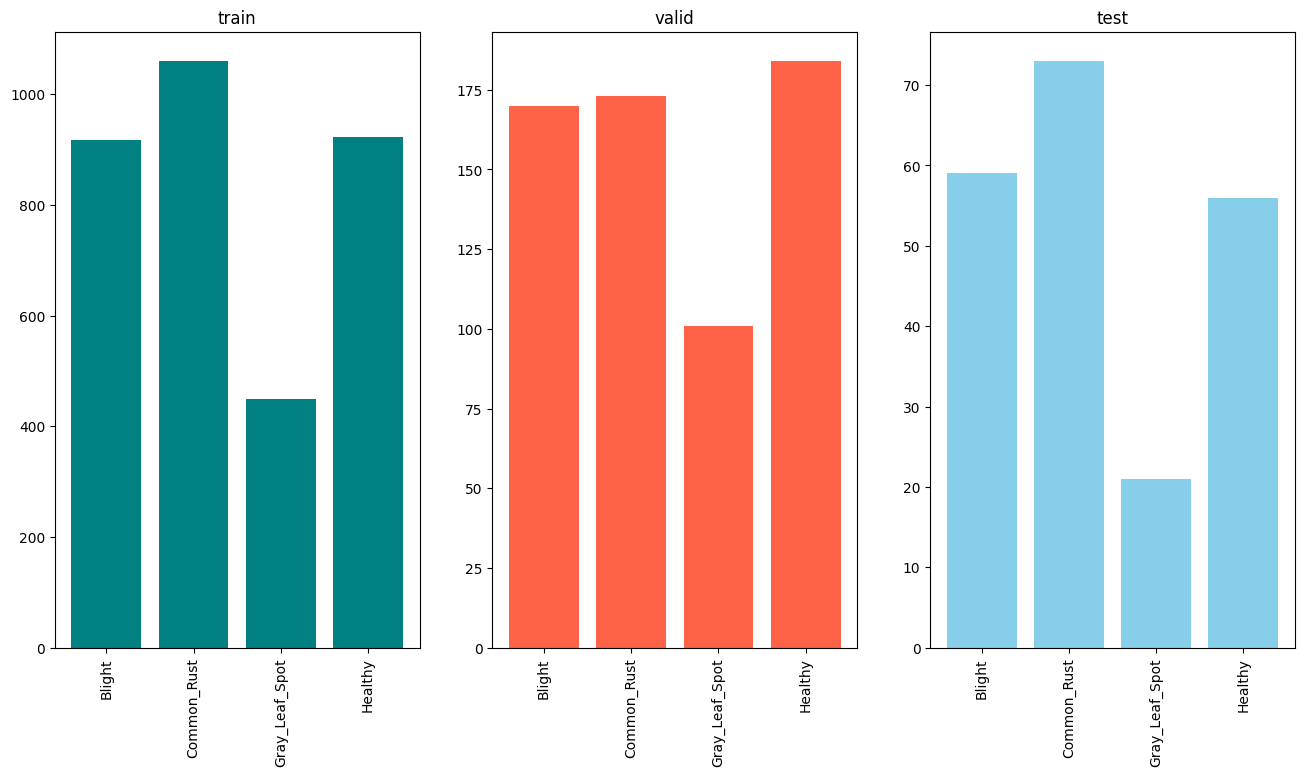

In [11]:
def distribution_plot(section:str):
    chart_labels= np.array([])

    for images, labels in data_loader[section]:
        labels = labels.numpy()
        chart_labels = np.hstack([chart_labels, labels])

    info = np.unique_counts(chart_labels)
    values = list(map(name, info.values.astype(int)))
    counts = info.counts
    return values, counts

values_train, counts_train = distribution_plot("train")
values_valid, counts_valid = distribution_plot("valid")
values_test, counts_test = distribution_plot("test")

plt.figure(figsize=(16,8))
plt.subplot(131);plt.bar(x=values_train, height=counts_train, color="teal");plt.title("train");plt.xticks(rotation=90)
plt.subplot(132);plt.bar(x=values_valid, height=counts_valid, color="tomato");plt.title("valid");plt.xticks(rotation=90)
plt.subplot(133);plt.bar(x=values_test, height=counts_test, color="skyblue");plt.title("test");plt.xticks(rotation=90)
plt.show()

In [12]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.early_stop = False
        self.counter = 0
        self.best_model_state = None

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.best_model_state = model.state_dict()
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = model.state_dict()
            self.counter = 0

    def load_best_model(self, model):
        model.load_state_dict(self.best_model_state)

In [13]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 16, 3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2))

        self.conv2 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2),
            nn.Dropout(0.2))

        self.conv3 = nn.Sequential(
            nn.Conv2d(32,64,3),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2))

        self.conv4 = nn.Sequential(
            nn.Conv2d(64,128,3),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.MaxPool2d(2,2),
            nn.Dropout(0.2))

        self.fc1 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*10*10,256),
            nn.ReLU())
        
        self.fc2 = nn.Sequential(
            nn.Linear(256,64),
            nn.ReLU(),
            nn.Dropout(0.2))
        
        self.fc3 = nn.Sequential(
            nn.Linear(64,4))

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)

        return x

model = Net()
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
early_stopping = EarlyStopping(patience=8, delta=0.01)
lr_scheduler_step = optim.lr_scheduler.StepLR(optimizer=optimizer, step_size=6, gamma=0.1)

summary(model, (3,200,200))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 198, 198]             448
       BatchNorm2d-2         [-1, 16, 198, 198]              32
              ReLU-3         [-1, 16, 198, 198]               0
         MaxPool2d-4           [-1, 16, 99, 99]               0
            Conv2d-5           [-1, 32, 97, 97]           4,640
       BatchNorm2d-6           [-1, 32, 97, 97]              64
         LeakyReLU-7           [-1, 32, 97, 97]               0
         MaxPool2d-8           [-1, 32, 48, 48]               0
           Dropout-9           [-1, 32, 48, 48]               0
           Conv2d-10           [-1, 64, 46, 46]          18,496
      BatchNorm2d-11           [-1, 64, 46, 46]             128
        LeakyReLU-12           [-1, 64, 46, 46]               0
        MaxPool2d-13           [-1, 64, 23, 23]               0
           Conv2d-14          [-1, 128,

In [14]:
epochs = 60

train_loss = []
train_accuracy = []
val_loss = []
val_accuracy = []


for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")

    total = 0
    correct = 0
    running_loss = 0.0

    model.train()
    for inputs, labels in data_loader['train']:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        predictions = torch.argmax(outputs, dim=1)

        loss.backward()
        optimizer.step()

        total += labels.size(0)
        running_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()

    train_accuracy.append(100 * correct / total)
    train_loss.append(running_loss / dataset_size['train'])

    lr_scheduler_step.step()
    print(f"Train Accuracy: {100 * correct/total:.2f}%   Train Loss: {running_loss/dataset_size['train']:.5f}")
    # ---------

    model.eval()
    with torch.no_grad():
        total = 0
        correct = 0
        running_loss = 0.0

        for inputs, labels in data_loader['valid']:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()
            running_loss += loss.item() * labels.size(0)

        val_accuracy.append(100 * correct / total)
        val_loss.append(running_loss / dataset_size['valid'])

        print(f"Val Accuracy: {correct/total:.2f}%   Val Loss: {running_loss/dataset_size['valid']:.5f}")


        early_stopping(running_loss/dataset_size['valid'], model=model)
        if early_stopping.early_stop:
            print("Early Stopping")
            break

print("Training Process got finish")
early_stopping.load_best_model(model)

torch.save(model.state_dict(), r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initial_model.pth")    

Epoch 1/60
Train Accuracy: 76.92%   Train Loss: 0.58114
Val Accuracy: 0.77%   Val Loss: 0.56627
Epoch 2/60
Train Accuracy: 84.29%   Train Loss: 0.36339
Val Accuracy: 0.77%   Val Loss: 0.51325
Epoch 3/60
Train Accuracy: 87.70%   Train Loss: 0.31162
Val Accuracy: 0.85%   Val Loss: 0.36264
Epoch 4/60
Train Accuracy: 90.71%   Train Loss: 0.24626
Val Accuracy: 0.87%   Val Loss: 0.32548
Epoch 5/60
Train Accuracy: 90.80%   Train Loss: 0.24010
Val Accuracy: 0.84%   Val Loss: 0.38876
Epoch 6/60
Train Accuracy: 93.10%   Train Loss: 0.18930
Val Accuracy: 0.88%   Val Loss: 0.31690
Epoch 7/60
Train Accuracy: 94.89%   Train Loss: 0.14488
Val Accuracy: 0.87%   Val Loss: 0.29355
Epoch 8/60
Train Accuracy: 95.55%   Train Loss: 0.12384
Val Accuracy: 0.89%   Val Loss: 0.26614
Epoch 9/60
Train Accuracy: 95.55%   Train Loss: 0.11768
Val Accuracy: 0.88%   Val Loss: 0.28686
Epoch 10/60
Train Accuracy: 95.61%   Train Loss: 0.11188
Val Accuracy: 0.88%   Val Loss: 0.28782
Epoch 11/60
Train Accuracy: 96.06%   Tr

In [16]:
with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\train_loss.npy", "wb") as f:
    np.save(f, train_loss)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\train_accuracy.npy", "wb") as f:
    np.save(f, train_accuracy)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\val_loss.npy", "wb") as f:
    np.save(f, val_loss)

with open(r"C:\Users\wwwat\Desktop\Corn Leaf Disease\initail model\val_accuracy.npy", "wb") as f:
    np.save(f, val_accuracy)